# Polymarket EDA

## Preamble

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

## Load data

In [10]:
# Open the database
con = sqlite3.connect("../polymarket-scraper/events.db")

In [11]:
# Read SQL db into DataFrame
df = pd.read_sql("SELECT * FROM events",con)

## Clean Data

In [12]:
print(df.columns)

Index(['id', 'ticker', 'slug', 'title', 'description', 'resolutionSource',
       'startDate', 'creationDate', 'endDate', 'image', 'icon', 'active',
       'closed', 'archived', 'new', 'featured', 'restricted', 'liquidity',
       'volume', 'openInterest', 'sortBy', 'category', 'published_at',
       'createdAt', 'updatedAt', 'competitive', 'volume24hr', 'volume1wk',
       'volume1mo', 'volume1yr', 'liquidityAmm', 'liquidityClob',
       'commentCount', 'markets', 'series', 'tags', 'cyom', 'closedTime',
       'showAllOutcomes', 'showMarketImages', 'enableNegRisk', 'seriesSlug',
       'negRiskAugmented', 'pendingDeployment', 'deploying',
       'requiresTranslation', 'eventMetadata', 'subcategory', 'updatedBy',
       'commentsEnabled', 'enableOrderBook', 'featuredImage', 'disqusThread',
       'automaticallyActive', 'negRisk', 'automaticallyResolved', 'createdBy',
       'negRiskMarketID', 'gmpChartMode', 'estimateValue', 'cumulativeMarkets',
       'startTime', 'eventDate', 'eventW

In [23]:
import sqlite3
import pandas as pd
import json
import ast

conn = sqlite3.connect('../polymarket-scraper/events.db')

# Pull the events table
events_df = pd.read_sql_query("SELECT id, title, markets FROM events LIMIT 20", conn)

for index, row in events_df.iterrows():
    print(f"Event: {row['title']}")
    
    # Parse the JSON string in the 'markets' column
    markets_data = json.loads(row['markets'])
    
    for market in markets_data:
        # The 'clobTokenIds' are typically stored as a stringified list in the JSON
        token_ids_str = market.get('clobTokenIds', '[]')
        
        # safely evaluate the string representation of the list into an actual Python list
        try:
            token_ids = ast.literal_eval(token_ids_str)
        except (ValueError, SyntaxError):
            token_ids = []
            
        print(f"  - Market: {market.get('question')}")
        print(f"  - 'Yes' Token: {token_ids[0] if len(token_ids) > 0 else 'N/A'}")
        print(f"  - 'No' Token: {token_ids[1] if len(token_ids) > 1 else 'N/A'}")

Event: NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?
  - Market: NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?
  - 'Yes' Token: 28182404005967940652495463228537840901055649726248190462854914416579180110833
  - 'No' Token: 47044845753450022047436429968808601130811164131571549682541703866165095016290
Event: NFL: Will the Falcons beat the Panthers by more than 3.5 points in their October 31st matchup?
  - Market: NFL: Will the Falcons beat the Panthers by more than 3.5 points in their October 31st matchup?
  - 'Yes' Token: 56511259653855886659936827966786013545784841144903847037967986812745595430432
  - 'No' Token: 14941478295244605382100055235924143559218628579320890713621951655794746924521
Event: (In-Game Trading) Will the 49ers beat the Packers by more than 3.5 points in their week three matchup?
  - Market: (In-Game Trading) Will the 49ers beat the Packers by more than 3.5 points in the

0           https://www.nba.com/games
1         https://www.nfl.com/scores/
2         https://www.nfl.com/scores/
3             https://norwaychess.no/
4                http://nba.com/games
                     ...             
386248                               
386249                               
386250                               
386251                               
386252                               
Name: resolutionSource, Length: 386253, dtype: str

closed
True     375653
False     10600
Name: count, dtype: Int64

In [15]:
# Set the correct type for boolean columns
boolean_columns = (
    "active",
    "closed",
    "archived",
    "new",
    "featured",
    "restricted",
    "commentsEnabled",
    "enableOrderBook",
    "negRisk",
    "cyom",
    "showAllOutcomes",
    "showMarketImages",
    "automaticallyResolved",
    "enableNegRisk",
    "automaticallyActive",
    "live",
    "ended",
    "estimateValue",
    "cantEstimate",
    "pendingDeployment",
    "deploying"
)

df[[*boolean_columns]] = df[[*boolean_columns]].astype('boolean')

In [16]:
# Parse the string JSON values
object_columns = (
    "markets",
    "tags",
    "eventCreators",
)

In [17]:
def parse_json(json_str : str) : 
    return json.loads(json_str) if isinstance(json_str,str) else np.nan
    
df[[*object_columns]] = df[[*object_columns]].map(parse_json)

In [18]:
df[[*object_columns]]

,markets,tags,eventCreators
0,"[{'id': '239826', 'question': 'NBA: Will the M...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
1,"[{'id': '239167', 'question': 'NFL: Will the F...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
2,"[{'id': '238885', 'question': '(In-Game Tradin...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
3,"[{'id': '245948', 'question': '2022 Norway Che...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
4,"[{'id': '239496', 'question': 'NBA: Will the H...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
...,...,...,...
386248,"[{'id': '255435', 'question': 'Trump $83.3m ve...","[{'id': '164', 'label': 'law', 'slug': 'law', ...",NaN
386249,"[{'id': '255440', 'question': 'Boeing whistleb...","[{'id': '846', 'label': 'Boeing', 'slug': 'boe...",NaN
386250,"[{'id': '255443', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
386251,"[{'id': '255447', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN


In [19]:
print(df.iloc[0]['markets'])

[{'id': '239826', 'question': 'NBA: Will the Mavericks beat the Grizzlies by more than 5.5 points in their December 4 matchup?', 'conditionId': '0x064d33e3f5703792aafa92bfb0ee10e08f461b1b34c02c1f02671892ede1609a', 'slug': 'nba-will-the-mavericks-beat-the-grizzlies-by-more-than-5pt5-points-in-their-december-4-matchup', 'resolutionSource': 'https://www.nba.com/games', 'endDate': '2021-12-04T00:00:00Z', 'category': 'Sports', 'liquidity': '50.000009', 'startDate': '2021-12-04T19:35:03.796Z', 'fee': '20000000000000000', 'image': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png', 'icon': 'https://polymarket-upload.s3.us-east-2.amazonaws.com/nba-will-the-mavericks-beat-the-grizzlies-by-more-than-55-points-in-their-december-4-matchup-aa2992d1-38df-404a-9190-49a909775014.png', 'description': 'In the upcoming NBA game, scheduled for December 4:\n\nIf the Dall

## Preliminary Analysis

### General statistics for interesting numerical columns

In [20]:
interesting_columns = (
    "liquidity",
    "volume",
    "openInterest",
    "volume24hr",
    "volume1wk",
    "volume1mo",
    "volume1yr",
    "commentCount",
)

### Addressing Hypothesis: Are a majority of high-volume markets related to Sports?
To answer this, let's look at the distribution of trading volume across the top categories.

/tmp/ipykernel_4009321/476895858.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')


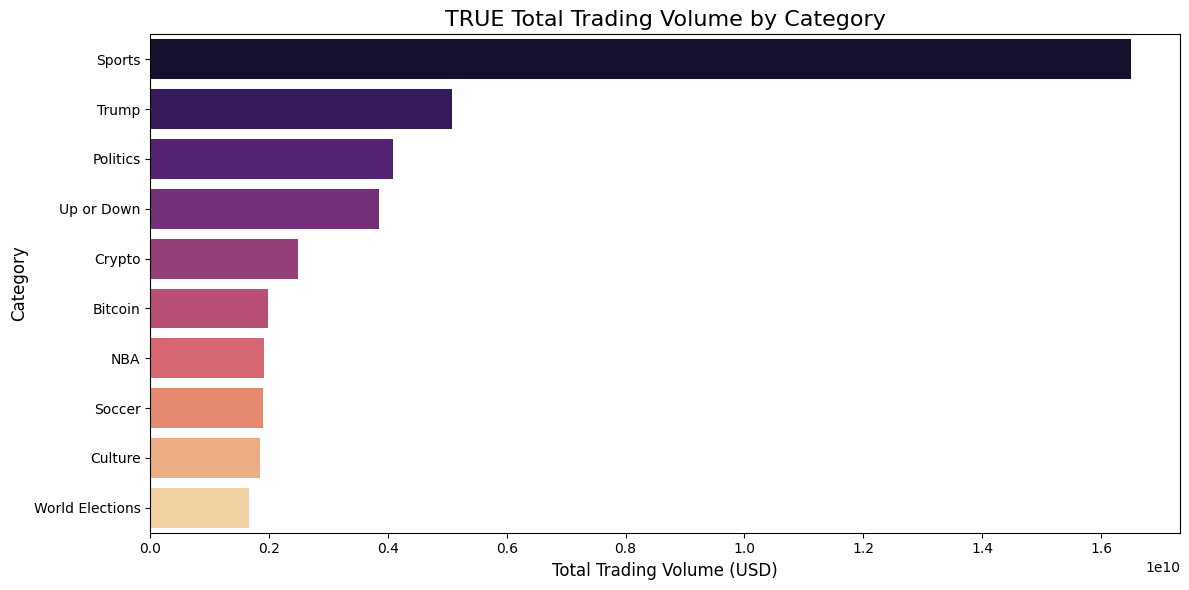

Top 10 True Categories by % of Total Volume:
primary_category
Sports             24.39%
Trump               7.52%
Politics            6.03%
Up or Down          5.70%
Crypto              3.68%
Bitcoin             2.93%
NBA                 2.84%
Soccer              2.80%
Culture             2.74%
World Elections     2.46%
Name: volume, dtype: str


In [21]:
# extraction of the 'Primary Category' from the tags list
def extract_primary_category(row):
    # If the standard category exists, use it
    if pd.notna(row['category']) and row['category'] != '':
        return row['category']
    
    # Otherwise, parse the tags column if it's a valid list of dictionaries
    if isinstance(row['tags'], list) and len(row['tags']) > 0:
        # We can extract the label from the first tag 
        # (usually the broadest/most representative tag)
        return row['tags'][0].get('label', 'Unknown')
        
    return 'Unknown'

# Apply our custom extractor
df['primary_category'] = df.apply(extract_primary_category, axis=1)

# Now, recalculate the volume with our newly populated categories!
total_volume = df['volume'].sum()
true_category_volume = df.groupby('primary_category')['volume'].sum().sort_values(ascending=False).head(10)

# Plotting the adjusted data
plt.figure(figsize=(12, 6))
sns.barplot(x=true_category_volume.values, y=true_category_volume.index, palette='magma')
plt.title('TRUE Total Trading Volume by Category', fontsize=16)
plt.xlabel('Total Trading Volume (USD)', fontsize=12)
plt.ylabel('Category', fontsize=12)
# formatter = ticker.FuncFormatter(lambda x, pos: f'${x*1e-9:,.1f}B') # Format to Billions now!
# plt.gca().xaxis.set_major_formatter(formatter)
plt.tight_layout()
plt.show()

# Print the real percentages
print("Top 10 True Categories by % of Total Volume:")
print((true_category_volume / total_volume * 100).apply(lambda x: f"{x:.2f}%"))

In [22]:
# Check the date intervals for the events data
date_columns = ['startDate', 'endDate', 'createdAt']

# Convert to datetime to easily find min and max limits
for col in date_columns:
    if col in df.columns:
        # Convert to datetime, coercing errors to NaT
        df[col] = pd.to_datetime(df[col], errors='coerce')

print("=== Data Date Intervals ===")
if 'createdAt' in df.columns:
    print(f"Earliest Event Created: {df['createdAt'].min()}")
    print(f"Latest Event Created:   {df['createdAt'].max()}")
    print("-" * 25)

if 'startDate' in df.columns:
    print(f"Earliest Start Date:    {df['startDate'].min()}")
    print(f"Latest Start Date:      {df['startDate'].max()}")
    print("-" * 25)

if 'endDate' in df.columns:
    print(f"Earliest End Date:      {df['endDate'].min()}")
    print(f"Latest End Date:        {df['endDate'].max()}")


=== Data Date Intervals ===
Earliest Event Created: 2022-07-27 14:40:02.074000+00:00
Latest Event Created:   2026-04-19 21:17:00.973232+00:00
-------------------------
Earliest Start Date:    2020-10-02 00:00:00+00:00
Latest Start Date:      2026-04-17 22:00:26+00:00
-------------------------
Earliest End Date:      0024-01-15 00:00:00+00:00
Latest End Date:        2029-01-20 00:00:00+00:00
